# Tugas 05 — Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas

**Nama:** Kevin Sukias K
**NIM:** 2802526416

Dataset: Oxford-IIIT Pet, subset 10 kelas (5 kucing + 5 anjing), split stratified 70/15/15.
Arsitektur utama: ResNet-18. Pembanding (B5): EfficientNet-B0 dan MobileNetV3-Small.

| Kode | Kondisi |
|---|---|
| B1 | Baseline from scratch (`weights=None`) |
| B2 | Feature extraction (backbone beku, hanya `fc`) |
| B3 | Progressive fine-tuning (`layer4` + `fc`, differential LR 1e-4 / 1e-3) |
| B4 | Uji kontrol augmentasi pada B3 (dengan vs. tanpa augmentasi) |
| B5 | Konfigurasi terbaik (dipilih via **validasi**) pada EfficientNet-B0 & MobileNetV3-Small |



Optimasi kecil yang dipakai:
- Citra di-*cache* di RAM setelah resize sisi pendek ke 256 px, jadi decoding JPEG hanya sekali.
- *Mixed precision* (AMP) + `channels_last` saat ada GPU.
- BatchNorm pada lapisan beku di-set `eval()` supaya *running stats* ImageNet tidak bergeser.
- B3 dipakai ulang sebagai skenario "dengan augmentasi" di B4 (konfigurasi & seed identik).

## 0. Setup

In [1]:
import os, json, time, copy, random, platform, shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import functional as TF

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# ===== Konfigurasi (protokol 4.2) =====
CFG = {
    "seed": 42,
    "img_size": 224,
    "batch_size": 32,
    "optimizer": "AdamW",
    "weight_decay": 1e-2,
    "loss": "CrossEntropyLoss",
    "max_epochs": 40,          # batas atas, biasanya berhenti duluan karena early stopping
    "early_stopping": "val_loss",
    "patience": 5,
    "min_delta": 1e-4,
    "lr_scratch": 1e-3,        # B1
    "lr_head": 1e-3,           # fc / classifier
    "lr_backbone": 1e-4,       # layer4 / blok terakhir
    "split": [0.70, 0.15, 0.15],
    "num_workers": 2,          # kalau error di Windows, set ke 0
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std": [0.229, 0.224, 0.225],
}
SEED = CFG["seed"]

USE_DRIVE = False   # True = simpan output ke Google Drive (aman kalau Colab putus)
OUT_DIR = Path("outputs")
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/Tugas05_outputs")
LOG_DIR, FIG_DIR, PRED_DIR, CKPT_DIR = (OUT_DIR / d for d in ["logs", "figures", "predictions", "checkpoints"])
for d in [LOG_DIR, FIG_DIR, PRED_DIR, CKPT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

ENV = {
    "python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
    "device": str(device), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "amp": USE_AMP, "seed": SEED,
}
print(json.dumps(ENV, indent=2))

{
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "device": "cuda",
  "gpu": "Tesla T4",
  "amp": true,
  "seed": 42
}


In [2]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # deterministik sedikit lebih lambat, tapi hasil bisa diulang
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

set_seed()

## 1. Dataset

Split bawaan `trainval` dan `test` digabung dulu (±200 citra/kelas), lalu dibagi ulang secara *stratified* 70/15/15.

**Pemilihan kelas.** Kelas sengaja dipilih supaya ada pasangan yang mirip secara visual, jadi eksperimennya tidak terlalu "mudah" dan failure analysis (C3) punya kasus yang bermakna:
- Kucing: **Bengal – Egyptian Mau** (sama-sama bulu bertotol), **British Shorthair – Russian Blue** (sama-sama abu-abu), dan Persian.
- Anjing: **Beagle – Basset Hound** (warna tricolor mirip), Boxer, Pug, dan Shiba Inu.

In [3]:
raw_splits = [OxfordIIITPet("./data", split=s, target_types="category", download=True)
              for s in ("trainval", "test")]
ALL_CLASSES = raw_splits[0].classes
print(len(ALL_CLASSES), "kelas total")

100%|██████████| 792M/792M [00:19<00:00, 40.2MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 14.2MB/s]


37 kelas total


In [4]:
CAT_BREEDS = ["Bengal", "Egyptian Mau", "British Shorthair", "Russian Blue", "Persian"]
DOG_BREEDS = ["Beagle", "Basset Hound", "Boxer", "Pug", "Shiba Inu"]
CLASS_NAMES = CAT_BREEDS + DOG_BREEDS
NUM_CLASSES = len(CLASS_NAMES)
missing = [c for c in CLASS_NAMES if c not in ALL_CLASSES]
assert not missing, f"Nama kelas tidak ditemukan: {missing}"
CFG["classes"] = CLASS_NAMES

# mapping index asli (0..36) -> index baru (0..9)
old2new = {raw_splits[0].class_to_idx[c]: i for i, c in enumerate(CLASS_NAMES)}

paths, labels = [], []
for ds in raw_splits:
    # _images & _labels adalah atribut internal torchvision (list path & label)
    for p, l in zip(ds._images, ds._labels):
        if l in old2new:
            paths.append(str(p))
            labels.append(old2new[l])
paths, labels = np.array(paths), np.array(labels)
print("Total citra subset:", len(paths))

Total citra subset: 1989


In [5]:
# Cache ke RAM: resize sisi pendek ke 256 sekali saja (sama dengan Resize(256) di pipeline)
images = [TF.resize(Image.open(p).convert("RGB"), 256) for p in tqdm(paths, desc="Load & cache")]

Load & cache:   0%|          | 0/1989 [00:00<?, ?it/s]

In [6]:
idx = np.arange(len(labels))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=labels[tmp_idx], random_state=SEED)

# cek kebocoran data: tidak ada citra yang muncul di dua split
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

split_col = np.empty(len(labels), dtype=object)
split_col[train_idx], split_col[val_idx], split_col[test_idx] = "train", "val", "test"
manifest = pd.DataFrame({"path": paths, "label": labels, "class": [CLASS_NAMES[l] for l in labels], "split": split_col})
manifest.to_csv(OUT_DIR / "split_manifest.csv", index=False)

dist = manifest.pivot_table(index="class", columns="split", values="path", aggfunc="count").loc[CLASS_NAMES, ["train", "val", "test"]]
dist.loc["TOTAL"] = dist.sum()
dist

split,train,val,test
class,,,
Bengal,140,30,30
Egyptian Mau,133,28,29
British Shorthair,140,30,30
Russian Blue,140,30,30
Persian,140,30,30
Beagle,140,30,30
Basset Hound,140,30,30
Boxer,139,30,30
Pug,140,30,30


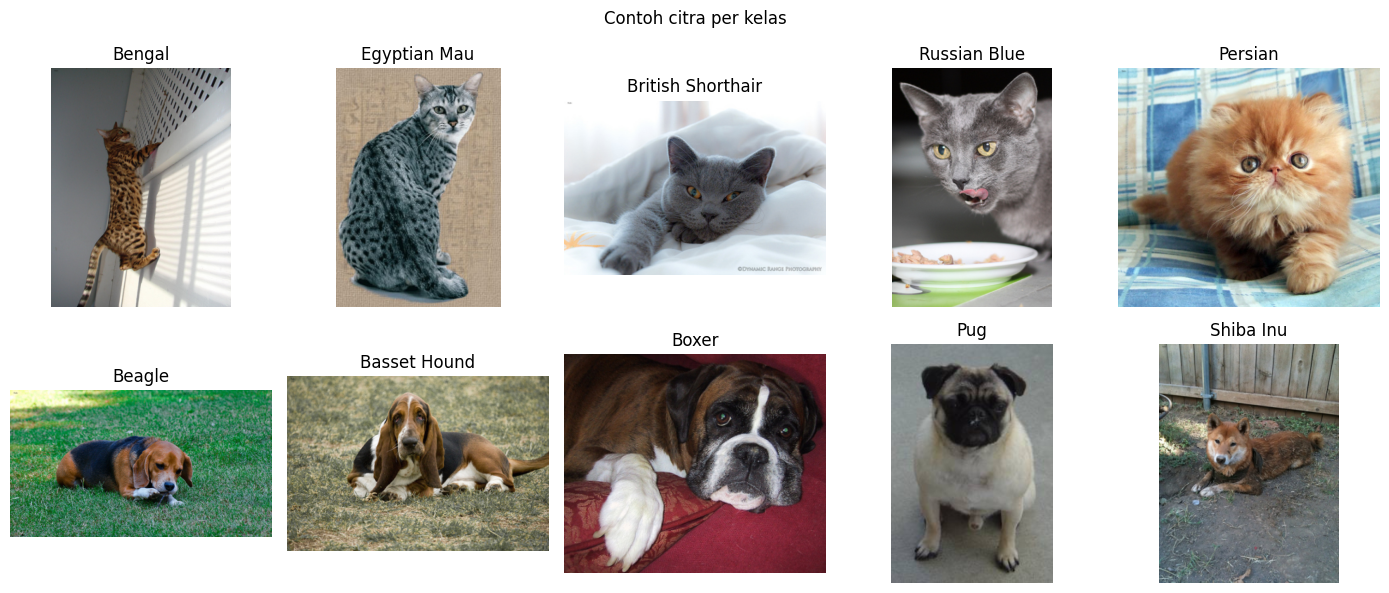

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for c, ax in enumerate(axes.flat):
    i = train_idx[labels[train_idx] == c][0]
    ax.imshow(images[i]); ax.set_title(CLASS_NAMES[c]); ax.axis("off")
plt.suptitle("Contoh citra per kelas"); plt.tight_layout()
plt.savefig(FIG_DIR / "sample_per_class.png", dpi=120); plt.show()

In [8]:
with open(OUT_DIR / "config.json", "w") as f:
    json.dump({"config": CFG, "env": ENV}, f, indent=2)

## 2. Starter code (dari soal)

Kode awal dari soal dijalankan apa adanya sebagai sanity check. Di bagian 3, pola yang sama dibungkus jadi fungsi supaya semua kondisi (B1–B5) memakai protokol yang identik.

In [9]:
# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

# 2. Konfigurasi B2: Feature Extraction (Bekukan Backbone)
for param in model.parameters():
    param.requires_grad = False

# Ganti classifier head untuk 10 kelas
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

trainable_b2 = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"B2 trainable params: {trainable_b2:,}")
assert trainable_b2 == 5_130   # sesuai tips di soal

# 3. Konfigurasi B3: Unfreeze Blok Residual Terakhir (layer4)
for param in model.layer4.parameters():
    param.requires_grad = True

# Optimasi dengan Differential Learning Rate
optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
], weight_decay=1e-2)

# 4. Pipeline Transformasi Data
# Data latih: menerapkan augmentasi aktif
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

# Data validasi/uji: hanya deterministik tanpa distorsi
eval_transforms = weights.transforms()

# Verifikasi parameter yang dapat dilatih
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,}")

del model, optimizer  # model dibangun ulang per eksperimen di bawah

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


B2 trainable params: 5,130
Trainable Parameters: 8,398,858 / 11,181,642


Untuk skenario **tanpa augmentasi** (B4), data latih memakai transformasi deterministik yang sama dengan validasi/uji (Resize 256 → CenterCrop 224 → Normalisasi). Augmentasi hanya pernah dipasang pada data latih.

In [10]:
train_transforms_noaug = eval_transforms
print(eval_transforms)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## 3. Dataset, DataLoader, dan fungsi bantu

In [11]:
class PetSubset(Dataset):
    def __init__(self, indices, tf):
        self.indices, self.tf = indices, tf
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        return self.tf(images[j]), labels[j]

def make_loader(indices, tf, shuffle):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(PetSubset(indices, tf), batch_size=CFG["batch_size"], shuffle=shuffle,
                      num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                      persistent_workers=CFG["num_workers"] > 0, worker_init_fn=seed_worker, generator=g)

val_loader        = make_loader(val_idx,   eval_transforms, shuffle=False)
test_loader       = make_loader(test_idx,  eval_transforms, shuffle=False)
train_eval_loader = make_loader(train_idx, eval_transforms, shuffle=False)  # akurasi train "bersih" (tanpa augmentasi)

In [12]:
def build_model(arch="resnet18", strategy="finetune"):
    """
    strategy:
      - "scratch"            : weights=None, semua parameter dilatih (B1)
      - "feature_extraction" : backbone beku, hanya linear head baru (B2)
      - "finetune"           : blok terakhir + head, differential LR (B3)
    """
    pretrained = strategy != "scratch"

    if arch == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        head, last_block = m.fc, m.layer4
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
        head = m.classifier[1]
        last_block = m.features[-2:]                     # stage MBConv terakhir + conv 1x1
    elif arch == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, NUM_CLASSES)
        head = m.classifier[3]
        # blok terakhir + Linear(576->1024) pretrained di classifier dianggap bagian "backbone"
        last_block = nn.ModuleList([m.features[-3:], m.classifier[0]])
    else:
        raise ValueError(arch)

    if strategy == "scratch":
        groups = [{"params": list(m.parameters()), "lr": CFG["lr_scratch"], "name": "all"}]
    else:
        for p in m.parameters():
            p.requires_grad = False
        for p in head.parameters():
            p.requires_grad = True
        groups = [{"params": list(head.parameters()), "lr": CFG["lr_head"], "name": "head"}]
        if strategy == "finetune":
            for p in last_block.parameters():
                p.requires_grad = True
            groups.insert(0, {"params": list(last_block.parameters()), "lr": CFG["lr_backbone"], "name": "last_block"})

    m = m.to(device, memory_format=torch.channels_last)
    return m, groups

def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable

# sanity check jumlah parameter tiap strategi sebelum training
for s in ["scratch", "feature_extraction", "finetune"]:
    m, _ = build_model("resnet18", s)
    print(f"resnet18 / {s:<19}: trainable {count_params(m)[1]:>11,} / {count_params(m)[0]:,}")
    del m

resnet18 / scratch            : trainable  11,181,642 / 11,181,642
resnet18 / feature_extraction : trainable       5,130 / 11,181,642
resnet18 / finetune           : trainable   8,398,858 / 11,181,642


In [13]:
criterion = nn.CrossEntropyLoss()

def freeze_bn_stats(model):
    # BN yang parameternya beku tetap pakai running stats ImageNet
    for mod in model.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

def run_epoch(model, loader, optimizer=None, scaler=None):
    is_train = optimizer is not None
    model.train(is_train)
    if is_train:
        freeze_bn_stats(model)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n

def fit(model, param_groups, train_loader):
    optimizer = torch.optim.AdamW(param_groups, weight_decay=CFG["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist = defaultdict(list)
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0

    t0 = time.time()
    for epoch in range(1, CFG["max_epochs"] + 1):
        t_ep = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader)
        hist["epoch"].append(epoch)
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc"], [tr_loss, tr_acc, va_loss, va_acc]):
            hist[k].append(v)
        hist["epoch_time_s"].append(time.time() - t_ep)
        for g in optimizer.param_groups:
            hist[f"lr_{g['name']}"].append(g["lr"])

        improved = va_loss < best_loss - CFG["min_delta"]
        print(f"Epoch {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f}"
              + ("  *" if improved else ""))
        if improved:
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= CFG["patience"]:
                print(f"Early stopping di epoch {epoch} (best epoch {best_epoch})")
                break
    train_time = time.time() - t0

    model.load_state_dict(best_state)  # pakai bobot dengan val loss terbaik
    lrs = ", ".join(f"{g['name']}={g['lr']:.0e}" for g in optimizer.param_groups)
    return pd.DataFrame(hist), dict(best_epoch=best_epoch, epochs_ran=epoch, train_time=train_time, lrs=lrs, best_val_loss=best_loss)

@torch.no_grad()
def predict(model, loader):
    """return y_true, y_pred, probs"""
    model.eval()
    ys, probs = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
        probs.append(out.float().softmax(1).cpu())
        ys.append(y)
    probs = torch.cat(probs).numpy()
    return torch.cat(ys).numpy(), probs.argmax(1), probs

@torch.no_grad()
def measure_latency(model, n_iter=50):
    """latensi inferensi 1 citra (ms), sebagai gambaran biaya komputasi"""
    model.eval()
    x = torch.randn(1, 3, 224, 224, device=device).to(memory_format=torch.channels_last)
    for _ in range(10):
        model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(n_iter):
        model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) / n_iter * 1000

In [14]:
results, histories, preds = {}, {}, {}

def save_summary():
    df = pd.DataFrame(results).T.reset_index(names="code")
    df.to_csv(OUT_DIR / "results_summary.csv", index=False)
    df.to_json(OUT_DIR / "results_summary.json", orient="records", indent=2)

def run_experiment(code_name, arch="resnet18", strategy="finetune", augment=True):
    print(f"\n===== {code_name} | {arch} | {strategy} | augment={augment} =====")
    set_seed(SEED)
    model, groups = build_model(arch, strategy)
    total, trainable = count_params(model)
    print(f"Trainable Parameters: {trainable:,} / {total:,}")

    train_loader = make_loader(train_idx, train_transforms if augment else train_transforms_noaug, shuffle=True)
    hist, info = fit(model, groups, train_loader)
    hist.insert(0, "code", code_name)
    hist.to_csv(LOG_DIR / f"{code_name}_epochs.csv", index=False)

    y_true, y_pred, probs = predict(model, test_loader)
    yt_tr, yp_tr, _ = predict(model, train_eval_loader)
    best = hist[hist["epoch"] == info["best_epoch"]].iloc[0]
    train_acc_clean = accuracy_score(yt_tr, yp_tr)

    results[code_name] = {
        "arch": arch, "strategy": strategy, "augmentation": augment,
        "total_params": total, "trainable_params": trainable, "lr_per_group": info["lrs"],
        "best_epoch": info["best_epoch"], "epochs_ran": info["epochs_ran"],
        "train_time_s": round(info["train_time"], 1),
        "train_acc_aug_at_best": best["train_acc"],      # akurasi pada batch latih (ter-augmentasi jika augment=True)
        "train_acc_clean": train_acc_clean,              # akurasi train tanpa augmentasi (adil untuk gap)
        "val_loss": info["best_val_loss"], "val_acc": best["val_acc"],
        "gap_train_val": train_acc_clean - best["val_acc"],
        "test_acc": accuracy_score(y_true, y_pred),
        "test_macro_f1": f1_score(y_true, y_pred, average="macro"),
        "latency_ms": round(measure_latency(model), 2),
    }
    histories[code_name] = hist
    preds[code_name] = (y_true, y_pred, probs)
    save_summary()

    pd.DataFrame({
        "path": paths[test_idx], "true": [CLASS_NAMES[i] for i in y_true], "pred": [CLASS_NAMES[i] for i in y_pred],
        "confidence": probs.max(1), "correct": y_true == y_pred,
    }).to_csv(PRED_DIR / f"{code_name}_test_predictions.csv", index=False)
    torch.save(model.state_dict(), CKPT_DIR / f"{code_name}.pt")

    r = results[code_name]
    print(f"-> val acc {r['val_acc']:.4f} | test acc {r['test_acc']:.4f} | test macro-F1 {r['test_macro_f1']:.4f} | {r['train_time_s']}s")
    del model
    if device.type == "cuda": torch.cuda.empty_cache()

def plot_history(codes, fname=None):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for c in codes:
        h = histories[c]
        axes[0].plot(h["epoch"], h["train_loss"], "--", label=f"{c} train"); axes[0].plot(h["epoch"], h["val_loss"], label=f"{c} val")
        axes[1].plot(h["epoch"], h["train_acc"], "--", label=f"{c} train");  axes[1].plot(h["epoch"], h["val_acc"], label=f"{c} val")
    axes[0].set_title("Loss"); axes[1].set_title("Accuracy")
    for ax in axes: ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=.3)
    plt.tight_layout()
    if fname: plt.savefig(FIG_DIR / fname, dpi=150)
    plt.show()

## 4. B1 — Baseline from Scratch

ResNet-18 dengan `weights=None`, seluruh parameter dilatih (lr 1e-3). Ini batas bawah.


===== B1 | resnet18 | scratch | augment=True =====
Trainable Parameters: 11,181,642 / 11,181,642
Epoch 01 | train loss 2.3577 acc 0.169 | val loss 2.4632 acc 0.211  *
Epoch 02 | train loss 2.0745 acc 0.267 | val loss 2.0574 acc 0.329  *
Epoch 03 | train loss 1.9875 acc 0.299 | val loss 2.4475 acc 0.248
Epoch 04 | train loss 1.9303 acc 0.312 | val loss 1.8654 acc 0.356  *
Epoch 05 | train loss 1.7197 acc 0.377 | val loss 1.8015 acc 0.369  *
Epoch 06 | train loss 1.6697 acc 0.392 | val loss 2.5091 acc 0.221
Epoch 07 | train loss 1.5868 acc 0.430 | val loss 1.9325 acc 0.356
Epoch 08 | train loss 1.5779 acc 0.448 | val loss 1.8483 acc 0.319
Epoch 09 | train loss 1.4583 acc 0.476 | val loss 1.7432 acc 0.376  *
Epoch 10 | train loss 1.3787 acc 0.491 | val loss 1.8967 acc 0.396
Epoch 11 | train loss 1.3550 acc 0.537 | val loss 3.5723 acc 0.292
Epoch 12 | train loss 1.2578 acc 0.546 | val loss 1.8940 acc 0.399
Epoch 13 | train loss 1.2358 acc 0.539 | val loss 1.9777 acc 0.426
Epoch 14 | train

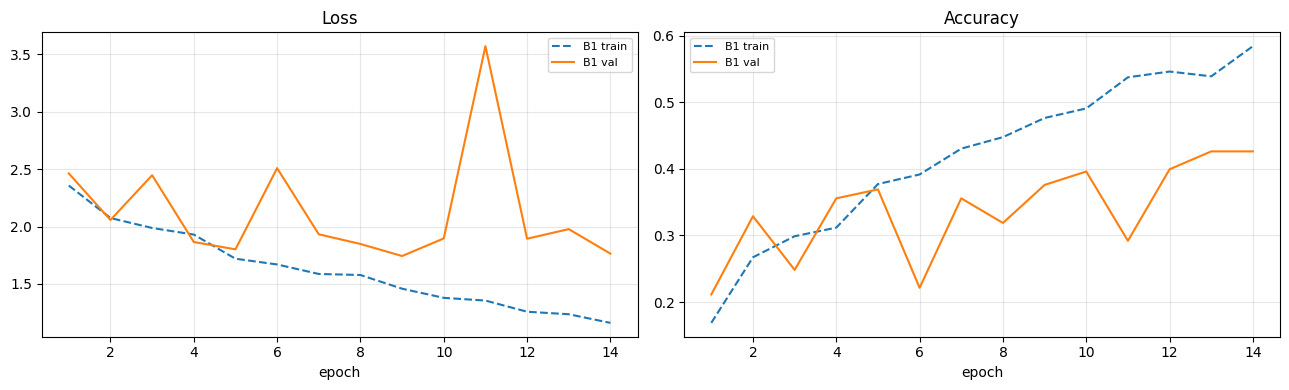

In [15]:
run_experiment("B1", "resnet18", "scratch", augment=True)
plot_history(["B1"])

## 5. B2 — Feature Extraction

Backbone pretrained dibekukan, hanya `fc` baru (`nn.Linear(512, 10)`) yang dilatih (lr 1e-3).


===== B2 | resnet18 | feature_extraction | augment=True =====
Trainable Parameters: 5,130 / 11,181,642
Epoch 01 | train loss 1.2569 acc 0.633 | val loss 0.6602 acc 0.809  *
Epoch 02 | train loss 0.5032 acc 0.879 | val loss 0.4258 acc 0.879  *
Epoch 03 | train loss 0.3734 acc 0.899 | val loss 0.3529 acc 0.886  *
Epoch 04 | train loss 0.2955 acc 0.920 | val loss 0.3173 acc 0.896  *
Epoch 05 | train loss 0.2677 acc 0.931 | val loss 0.2738 acc 0.903  *
Epoch 06 | train loss 0.2272 acc 0.940 | val loss 0.2809 acc 0.899
Epoch 07 | train loss 0.2190 acc 0.938 | val loss 0.2734 acc 0.889  *
Epoch 08 | train loss 0.1963 acc 0.947 | val loss 0.2286 acc 0.919  *
Epoch 09 | train loss 0.1646 acc 0.958 | val loss 0.2257 acc 0.913  *
Epoch 10 | train loss 0.1724 acc 0.957 | val loss 0.2317 acc 0.916
Epoch 11 | train loss 0.1697 acc 0.949 | val loss 0.2461 acc 0.913
Epoch 12 | train loss 0.1608 acc 0.951 | val loss 0.2214 acc 0.930  *
Epoch 13 | train loss 0.1504 acc 0.960 | val loss 0.2393 acc 0.90

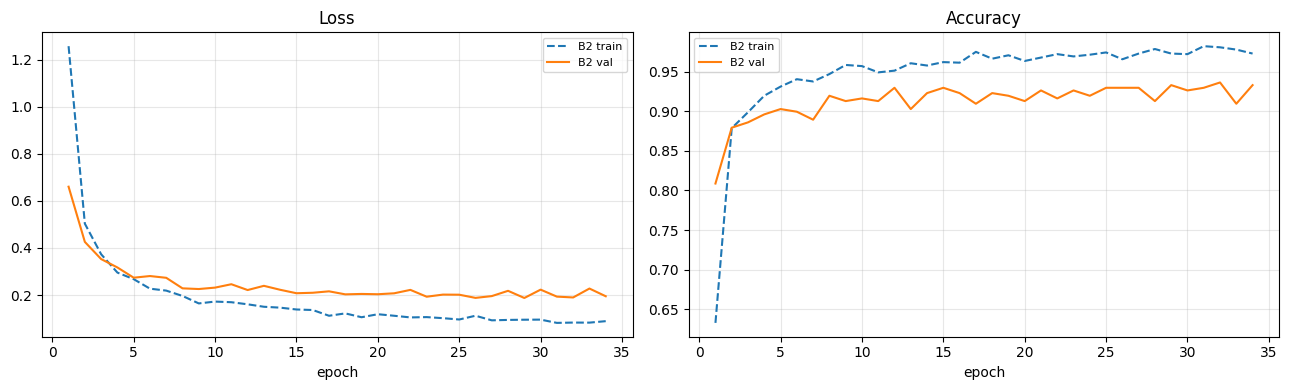

In [16]:
run_experiment("B2", "resnet18", "feature_extraction", augment=True)
plot_history(["B2"])

## 6. B3 — Progressive Fine-Tuning

`layer4` + `fc` dibuka dengan *differential learning rate*: 1e-4 untuk `layer4`, 1e-3 untuk `fc`.


===== B3 | resnet18 | finetune | augment=True =====
Trainable Parameters: 8,398,858 / 11,181,642
Epoch 01 | train loss 0.7409 acc 0.769 | val loss 0.2839 acc 0.886  *
Epoch 02 | train loss 0.1931 acc 0.951 | val loss 0.2652 acc 0.893  *
Epoch 03 | train loss 0.1416 acc 0.956 | val loss 0.2539 acc 0.906  *
Epoch 04 | train loss 0.0758 acc 0.979 | val loss 0.2378 acc 0.906  *
Epoch 05 | train loss 0.0511 acc 0.986 | val loss 0.2004 acc 0.923  *
Epoch 06 | train loss 0.0365 acc 0.991 | val loss 0.1988 acc 0.926  *
Epoch 07 | train loss 0.0229 acc 0.997 | val loss 0.2267 acc 0.930
Epoch 08 | train loss 0.0291 acc 0.993 | val loss 0.2541 acc 0.913
Epoch 09 | train loss 0.0233 acc 0.995 | val loss 0.2468 acc 0.916
Epoch 10 | train loss 0.0186 acc 0.996 | val loss 0.2467 acc 0.916
Epoch 11 | train loss 0.0173 acc 0.996 | val loss 0.3436 acc 0.896
Early stopping di epoch 11 (best epoch 6)
-> val acc 0.9262 | test acc 0.9365 | test macro-F1 0.9361 | 67.8s


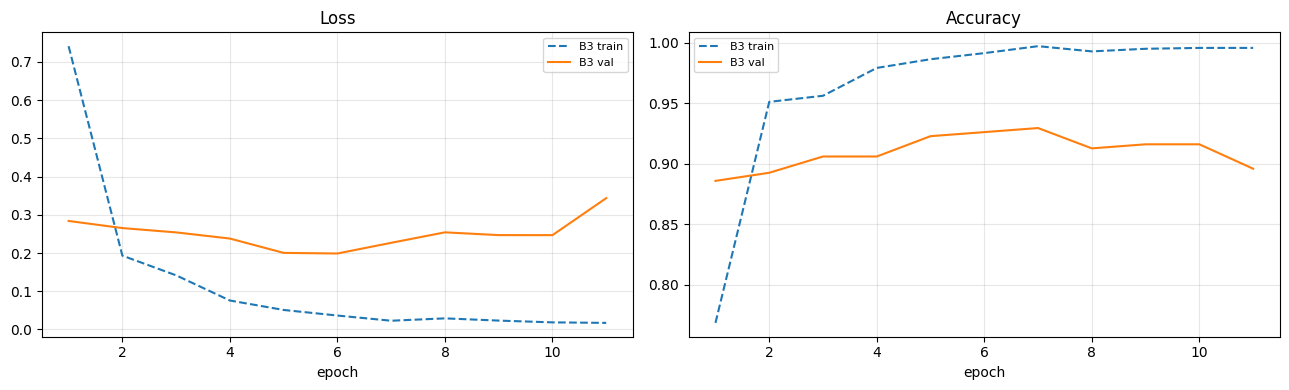

In [17]:
run_experiment("B3", "resnet18", "finetune", augment=True)
plot_history(["B3"])

## 7. B4 — Uji Kontrol Data Augmentation (berbasis B3)

- **Dengan augmentasi** = B3 (konfigurasi & seed identik, tidak dilatih ulang).
- **Tanpa augmentasi** = B3 dengan train transform hanya Resize/CenterCrop + Normalisasi.

Overfitting diukur dengan `gap_train_val` = akurasi train **tanpa augmentasi** − akurasi validasi. Akurasi train yang tercatat selama training dihitung pada batch ter-augmentasi, jadi untuk B3 nilainya lebih rendah dari akurasi sebenarnya dan tidak adil dipakai untuk gap.

In [18]:
run_experiment("B4_noaug", "resnet18", "finetune", augment=False)

b4 = pd.DataFrame(results).T.loc[["B3", "B4_noaug"], ["augmentation", "best_epoch", "train_acc_aug_at_best",
                                                      "train_acc_clean", "val_acc", "gap_train_val", "test_acc", "test_macro_f1"]]
b4.index = ["Dengan augmentasi (=B3)", "Tanpa augmentasi"]
b4


===== B4_noaug | resnet18 | finetune | augment=False =====
Trainable Parameters: 8,398,858 / 11,181,642
Epoch 01 | train loss 0.6696 acc 0.809 | val loss 0.2352 acc 0.909  *
Epoch 02 | train loss 0.1008 acc 0.980 | val loss 0.2259 acc 0.919  *
Epoch 03 | train loss 0.0349 acc 0.998 | val loss 0.2070 acc 0.930  *
Epoch 04 | train loss 0.0129 acc 1.000 | val loss 0.2024 acc 0.933  *
Epoch 05 | train loss 0.0065 acc 1.000 | val loss 0.2013 acc 0.930  *
Epoch 06 | train loss 0.0052 acc 1.000 | val loss 0.1962 acc 0.936  *
Epoch 07 | train loss 0.0033 acc 1.000 | val loss 0.2084 acc 0.933
Epoch 08 | train loss 0.0036 acc 1.000 | val loss 0.1946 acc 0.936  *
Epoch 09 | train loss 0.0024 acc 1.000 | val loss 0.2000 acc 0.940
Epoch 10 | train loss 0.0024 acc 1.000 | val loss 0.2064 acc 0.940
Epoch 11 | train loss 0.0023 acc 1.000 | val loss 0.2008 acc 0.936
Epoch 12 | train loss 0.0017 acc 1.000 | val loss 0.2030 acc 0.940
Epoch 13 | train loss 0.0013 acc 1.000 | val loss 0.2087 acc 0.936
Ear

,augmentation,best_epoch,train_acc_aug_at_best,train_acc_clean,val_acc,gap_train_val,test_acc,test_macro_f1
Dengan augmentasi (=B3),True,6,0.991379,0.994971,0.926174,0.068797,0.936455,0.936078
Tanpa augmentasi,False,8,1.0,1.0,0.936242,0.063758,0.943144,0.942544


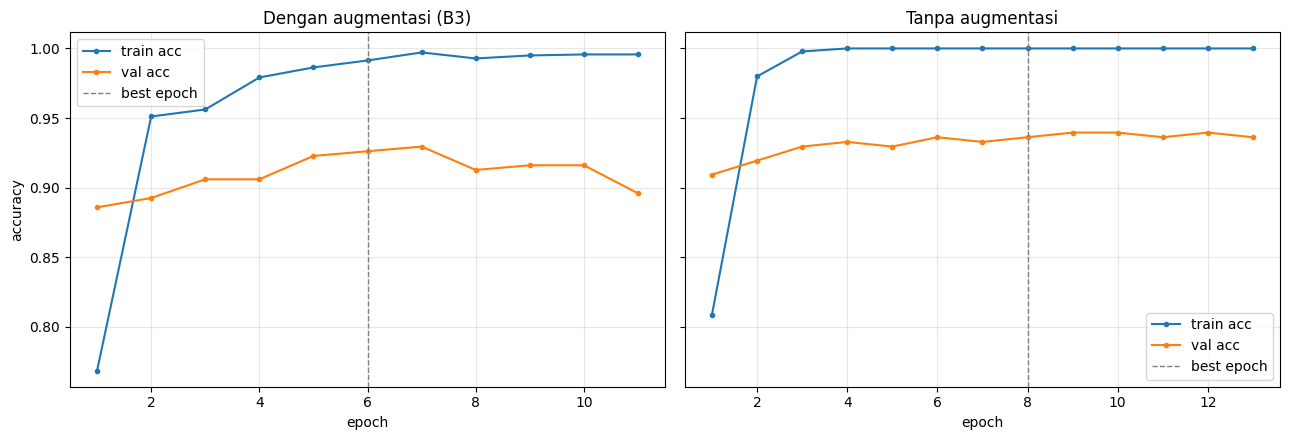

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, c, title in zip(axes, ["B3", "B4_noaug"], ["Dengan augmentasi (B3)", "Tanpa augmentasi"]):
    h = histories[c]
    ax.plot(h["epoch"], h["train_acc"], marker="o", ms=3, label="train acc")
    ax.plot(h["epoch"], h["val_acc"], marker="o", ms=3, label="val acc")
    ax.axvline(results[c]["best_epoch"], ls="--", c="gray", lw=1, label="best epoch")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("accuracy")
plt.tight_layout(); plt.savefig(FIG_DIR / "C2_B4_train_vs_val_acc.png", dpi=150); plt.show()

## 8. B5 (Bonus) — Arsitektur Pembanding

Konfigurasi terbaik dipilih dari run ResNet-18 yang **benar-benar dijalankan** (B2, B3, B4_noaug) berdasarkan **akurasi validasi** (tie-break: val loss terendah). Test set tidak dipakai untuk memilih apa pun.

In [20]:
candidates = ["B2", "B3", "B4_noaug"]
best_cfg = min(candidates, key=lambda c: (-results[c]["val_acc"], results[c]["val_loss"]))
BEST_STRATEGY = results[best_cfg]["strategy"]
BEST_AUG = bool(results[best_cfg]["augmentation"])
print(f"Konfigurasi terbaik (validasi): {best_cfg} -> strategy={BEST_STRATEGY}, augment={BEST_AUG}")

run_experiment("B5_effnet_b0", "efficientnet_b0", BEST_STRATEGY, augment=BEST_AUG)
run_experiment("B5_mnv3_small", "mobilenet_v3_small", BEST_STRATEGY, augment=BEST_AUG)

Konfigurasi terbaik (validasi): B4_noaug -> strategy=finetune, augment=False

===== B5_effnet_b0 | efficientnet_b0 | finetune | augment=False =====
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 130MB/s] 


Trainable Parameters: 1,142,202 / 4,020,358
Epoch 01 | train loss 1.0036 acc 0.776 | val loss 0.2919 acc 0.906  *
Epoch 02 | train loss 0.2491 acc 0.938 | val loss 0.2011 acc 0.946  *
Epoch 03 | train loss 0.1633 acc 0.955 | val loss 0.1958 acc 0.933  *
Epoch 04 | train loss 0.1071 acc 0.977 | val loss 0.1854 acc 0.933  *
Epoch 05 | train loss 0.0747 acc 0.981 | val loss 0.1414 acc 0.960  *
Epoch 06 | train loss 0.0636 acc 0.986 | val loss 0.1357 acc 0.950  *
Epoch 07 | train loss 0.0415 acc 0.995 | val loss 0.1441 acc 0.953
Epoch 08 | train loss 0.0427 acc 0.989 | val loss 0.1363 acc 0.960
Epoch 09 | train loss 0.0338 acc 0.992 | val loss 0.1429 acc 0.953
Epoch 10 | train loss 0.0309 acc 0.993 | val loss 0.1420 acc 0.956
Epoch 11 | train loss 0.0227 acc 0.996 | val loss 0.1458 acc 0.956
Early stopping di epoch 11 (best epoch 6)
-> val acc 0.9497 | test acc 0.9632 | test macro-F1 0.9631 | 41.0s

===== B5_mnv3_small | mobilenet_v3_small | finetune | augment=False =====
Downloading: "htt

100%|██████████| 9.83M/9.83M [00:00<00:00, 92.3MB/s]

Trainable Parameters: 1,245,738 / 1,528,106


Epoch 01 | train loss 1.0637 acc 0.716 | val loss 0.3763 acc 0.879  *
Epoch 02 | train loss 0.3117 acc 0.914 | val loss 0.3392 acc 0.886  *
Epoch 03 | train loss 0.1926 acc 0.944 | val loss 0.2455 acc 0.930  *
Epoch 04 | train loss 0.1168 acc 0.972 | val loss 0.2370 acc 0.930  *
Epoch 05 | train loss 0.0696 acc 0.990 | val loss 0.2382 acc 0.923
Epoch 06 | train loss 0.0483 acc 0.994 | val loss 0.2210 acc 0.926  *
Epoch 07 | train loss 0.0312 acc 0.998 | val loss 0.2134 acc 0.940  *
Epoch 08 | train loss 0.0250 acc 0.997 | val loss 0.2164 acc 0.940
Epoch 09 | train loss 0.0151 acc 1.000 | val loss 0.2290 acc 0.933
Epoch 10 | train loss 0.0133 acc 0.999 | val loss 0.2338 acc 0.926
Epoch 11 | train loss 0.0107 acc 1.000 | val loss 0.2337 acc 0.930
Epoch 12 | train loss 0.0102 acc 0.999 | val loss 0.2234 acc 0.943
Early stopping di epoch 12 (best epoch 7)
-> val acc 0.9396 | test acc 0.9130 | test macro-F1 0.9126 | 38.7s


,arch,total_params,trainable_params,train_time_s,latency_ms,val_acc,test_macro_f1
B4_noaug,resnet18,11181642,8398858,38.0,4.56,0.936242,0.942544
B5_effnet_b0,efficientnet_b0,4020358,1142202,41.0,8.58,0.949664,0.963097
B5_mnv3_small,mobilenet_v3_small,1528106,1245738,38.7,5.56,0.939597,0.91256


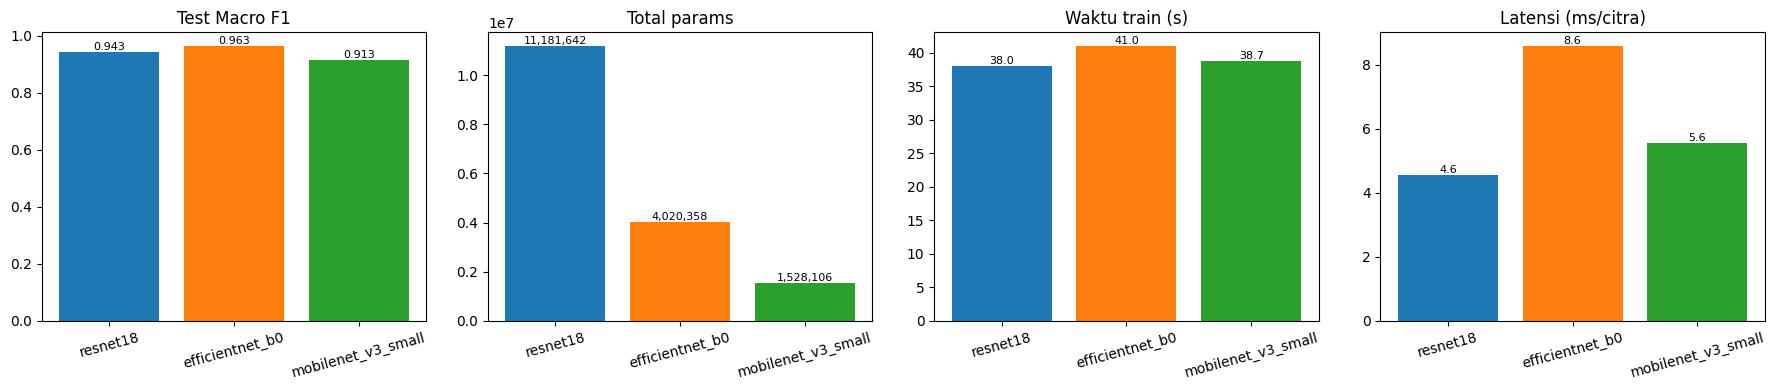

In [21]:
b5_codes = [best_cfg, "B5_effnet_b0", "B5_mnv3_small"]
b5 = pd.DataFrame(results).T.loc[b5_codes, ["arch", "total_params", "trainable_params", "train_time_s", "latency_ms", "val_acc", "test_macro_f1"]]
display(b5)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
names = b5["arch"].tolist()
for ax, col, title in zip(axes, ["test_macro_f1", "total_params", "train_time_s", "latency_ms"],
                          ["Test Macro F1", "Total params", "Waktu train (s)", "Latensi (ms/citra)"]):
    vals = b5[col].astype(float)
    ax.bar(names, vals, color=["tab:blue", "tab:orange", "tab:green"])
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:,.3f}" if col == "test_macro_f1" else f"{v:,.0f}" if v > 100 else f"{v:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(FIG_DIR / "B5_tradeoff.png", dpi=150); plt.show()

## 9. C1 — Tabel Konsolidasi dan Kurva Pembelajaran

In [22]:
order = ["B1", "B2", "B3", "B4_noaug", "B5_effnet_b0", "B5_mnv3_small"]
summary = pd.DataFrame(results).T.loc[order]
c1 = pd.DataFrame({
    "Kode": order,
    "Strategi": summary["strategy"].values,
    "Arsitektur": summary["arch"].values,
    "Augmentasi": summary["augmentation"].values,
    "Trainable params": summary["trainable_params"].map("{:,}".format).values,
    "LR per grup": summary["lr_per_group"].values,
    "Epoch konvergen (best)": summary["best_epoch"].values,
    "Epoch dijalankan": summary["epochs_ran"].values,
    "Waktu train (s)": summary["train_time_s"].values,
    "Val Acc": summary["val_acc"].astype(float).round(4).values,
    "Test Macro F1": summary["test_macro_f1"].astype(float).round(4).values,
})
c1.to_csv(OUT_DIR / "C1_tabel_konsolidasi.csv", index=False)
try:
    (OUT_DIR / "C1_tabel_konsolidasi.md").write_text(c1.to_markdown(index=False))
except ImportError:
    pass  # to_markdown butuh paket tabulate
c1

,Kode,Strategi,Arsitektur,Augmentasi,Trainable params,LR per grup,Epoch konvergen (best),Epoch dijalankan,Waktu train (s),Val Acc,Test Macro F1
0,B1,scratch,resnet18,True,"11,181,642",all=1e-03,9,14,95.5,0.3758,0.4241
1,B2,feature_extraction,resnet18,True,"5,130",head=1e-03,29,34,208.9,0.9329,0.9366
2,B3,finetune,resnet18,True,"8,398,858","last_block=1e-04, head=1e-03",6,11,67.8,0.9262,0.9361
3,B4_noaug,finetune,resnet18,False,"8,398,858","last_block=1e-04, head=1e-03",8,13,38.0,0.9362,0.9425
4,B5_effnet_b0,finetune,efficientnet_b0,False,"1,142,202","last_block=1e-04, head=1e-03",6,11,41.0,0.9497,0.9631
5,B5_mnv3_small,finetune,mobilenet_v3_small,False,"1,245,738","last_block=1e-04, head=1e-03",7,12,38.7,0.9396,0.9126


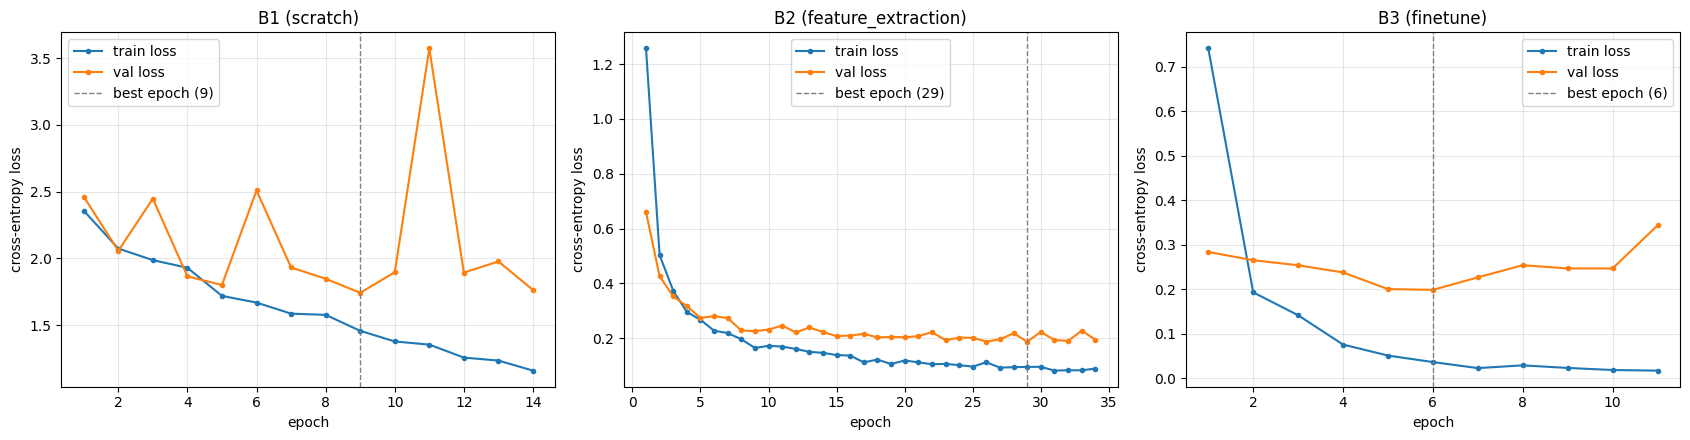

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, ["B1", "B2", "B3"]):
    h = histories[c]
    ax.plot(h["epoch"], h["train_loss"], marker="o", ms=3, label="train loss")
    ax.plot(h["epoch"], h["val_loss"], marker="o", ms=3, label="val loss")
    ax.axvline(results[c]["best_epoch"], ls="--", c="gray", lw=1, label=f"best epoch ({results[c]['best_epoch']})")
    ax.set_title(f"{c} ({results[c]['strategy']})"); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss")
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "C1_loss_curves_B1_B2_B3.png", dpi=150); plt.show()

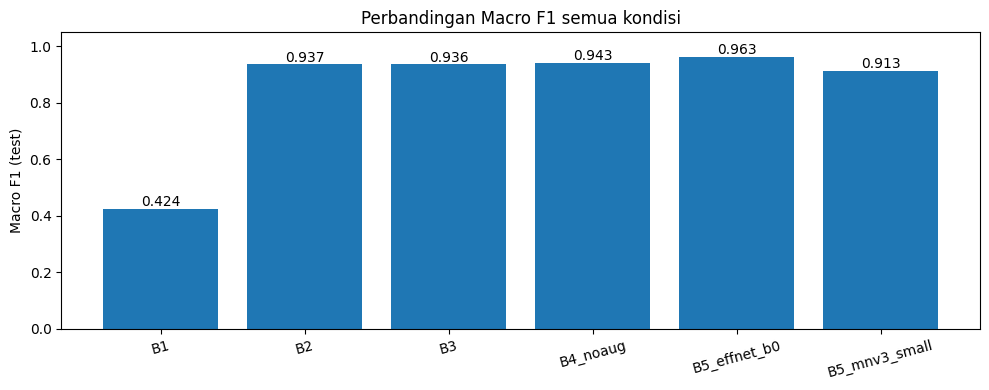

In [24]:
plt.figure(figsize=(10, 4))
f1s = summary["test_macro_f1"].astype(float)
plt.bar(order, f1s)
for i, v in enumerate(f1s):
    plt.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.ylim(0, 1.05); plt.ylabel("Macro F1 (test)"); plt.title("Perbandingan Macro F1 semua kondisi")
plt.xticks(rotation=15); plt.tight_layout(); plt.savefig(FIG_DIR / "C1_macro_f1_all.png", dpi=150); plt.show()

## 10. C3 — Failure Analysis

Model terbaik dipilih dari **semua run** berdasarkan akurasi validasi (tie-break val loss). Ditampilkan sampai 8 kesalahan dengan *confidence* tertinggi, karena kesalahan yang "yakin" biasanya paling informatif. Kolom `hipotesis` di `C3_misclassified.csv` diisi sendiri setelah melihat gambarnya.

Model terbaik (validasi): B5_effnet_b0
                   precision    recall  f1-score   support

           Bengal      0.931     0.900     0.915        30
     Egyptian Mau      0.931     0.931     0.931        29
British Shorthair      0.903     0.933     0.918        30
     Russian Blue      0.933     0.933     0.933        30
          Persian      0.968     1.000     0.984        30
           Beagle      0.968     1.000     0.984        30
     Basset Hound      1.000     0.967     0.983        30
            Boxer      1.000     1.000     1.000        30
              Pug      1.000     1.000     1.000        30
        Shiba Inu      1.000     0.967     0.983        30

         accuracy                          0.963       299
        macro avg      0.963     0.963     0.963       299
     weighted avg      0.964     0.963     0.963       299



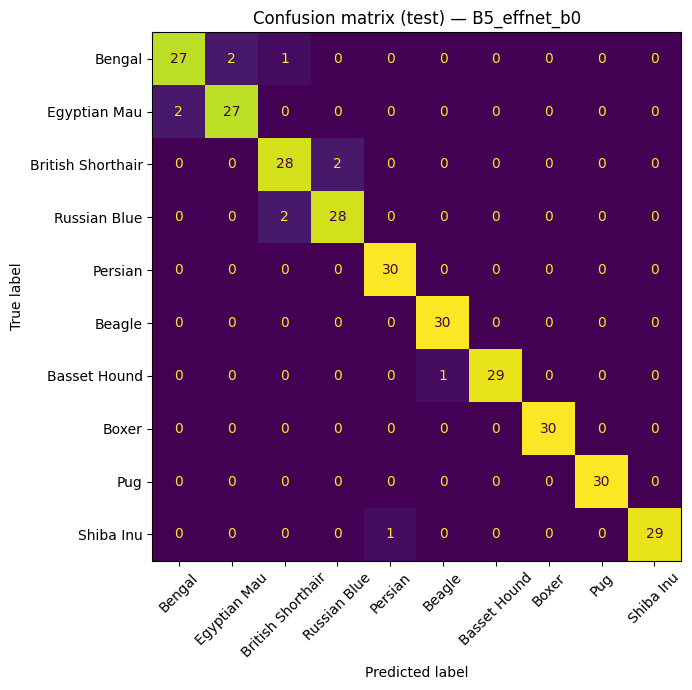

In [25]:
best_run = min(results, key=lambda c: (-results[c]["val_acc"], results[c]["val_loss"]))
y_true, y_pred, probs = preds[best_run]
print("Model terbaik (validasi):", best_run)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASS_NAMES).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion matrix (test) — {best_run}"); plt.tight_layout()
plt.savefig(FIG_DIR / "C3_confusion_matrix.png", dpi=150); plt.show()

Salah prediksi: 11 / 299; ditampilkan 8


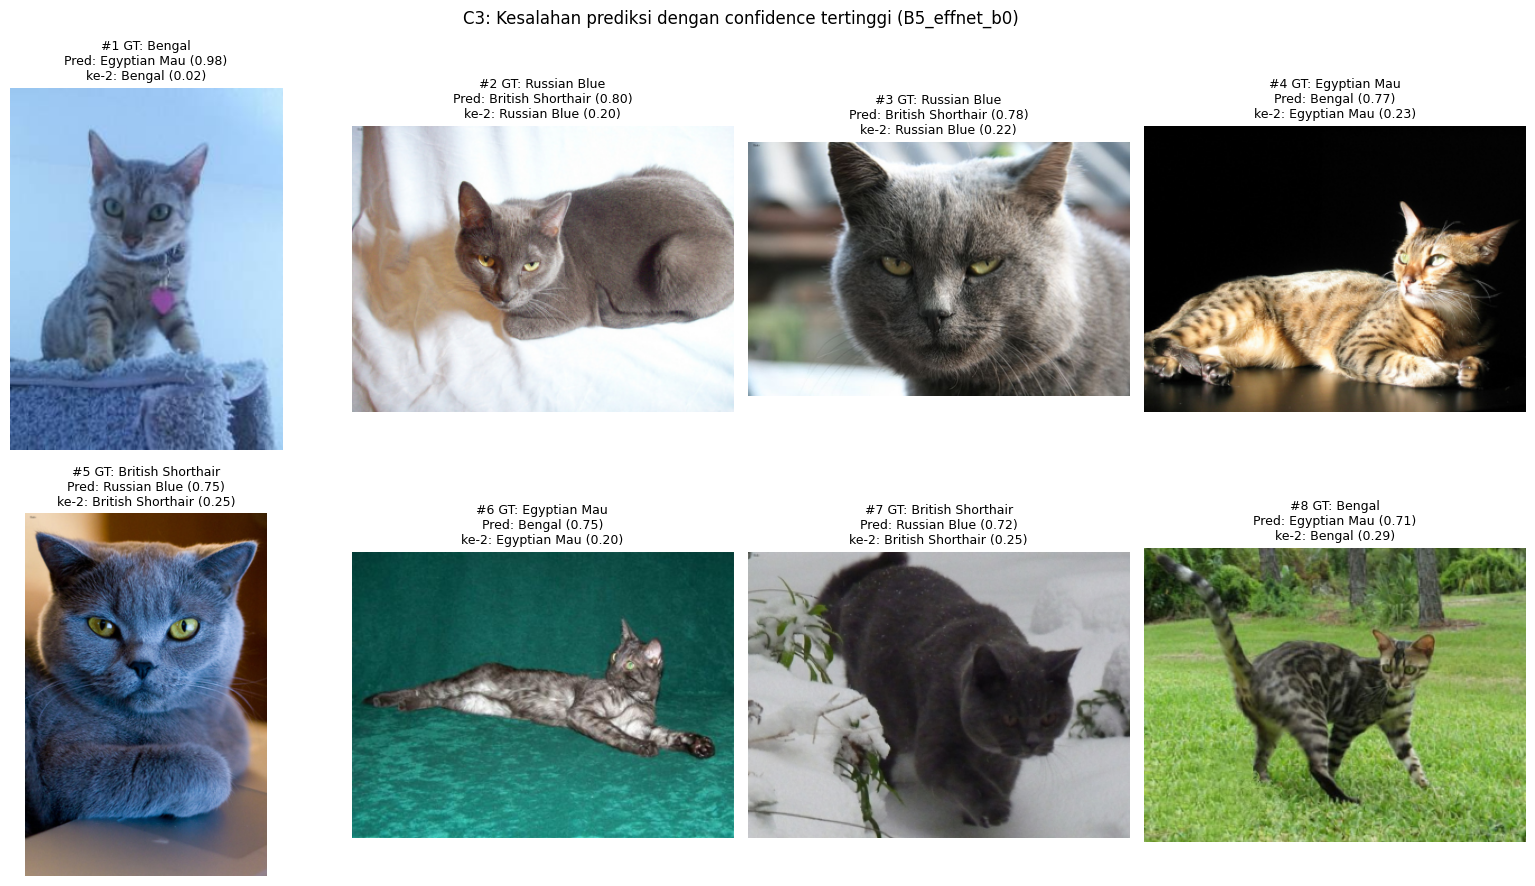

,no,file,ground_truth,prediksi,confidence,prediksi_ke2,prob_ke2,hipotesis
0,1,Bengal_166.jpg,Bengal,Egyptian Mau,0.9788,Bengal,0.0152,
1,2,Russian_Blue_176.jpg,Russian Blue,British Shorthair,0.7993,Russian Blue,0.2005,
2,3,Russian_Blue_29.jpg,Russian Blue,British Shorthair,0.7767,Russian Blue,0.2225,
3,4,Egyptian_Mau_63.jpg,Egyptian Mau,Bengal,0.7695,Egyptian Mau,0.2302,
4,5,British_Shorthair_168.jpg,British Shorthair,Russian Blue,0.7505,British Shorthair,0.2494,
5,6,Egyptian_Mau_101.jpg,Egyptian Mau,Bengal,0.7490,Egyptian Mau,0.1967,
6,7,British_Shorthair_34.jpg,British Shorthair,Russian Blue,0.7172,British Shorthair,0.2459,
7,8,Bengal_184.jpg,Bengal,Egyptian Mau,0.7072,Bengal,0.2914,


In [26]:
wrong = np.where(y_true != y_pred)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]       # kesalahan paling "yakin" dulu
print(f"Salah prediksi: {(y_true != y_pred).sum()} / {len(y_true)}; ditampilkan {len(wrong)}")
if len(wrong) < 5:
    print("Catatan: kurang dari 5 kesalahan di test set. Tampilkan juga kesalahan dari model kedua terbaik di laporan.")

rows = []
n_cols = 4
fig, axes = plt.subplots(max(1, int(np.ceil(len(wrong) / n_cols))), n_cols, figsize=(16, 4.5 * max(1, int(np.ceil(len(wrong) / n_cols)))), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for k, (ax, i) in enumerate(zip(axes.flat, wrong), start=1):
    j = test_idx[i]
    second = np.argsort(-probs[i])[1]
    ax.imshow(images[j])
    ax.set_title(f"#{k} GT: {CLASS_NAMES[y_true[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({probs[i].max():.2f})\n"
                 f"ke-2: {CLASS_NAMES[second]} ({probs[i][second]:.2f})", fontsize=9)
    rows.append({"no": k, "file": Path(paths[j]).name, "ground_truth": CLASS_NAMES[y_true[i]],
                 "prediksi": CLASS_NAMES[y_pred[i]], "confidence": round(float(probs[i].max()), 4),
                 "prediksi_ke2": CLASS_NAMES[second], "prob_ke2": round(float(probs[i][second]), 4), "hipotesis": ""})
plt.suptitle(f"C3: Kesalahan prediksi dengan confidence tertinggi ({best_run})")
plt.tight_layout(); plt.savefig(FIG_DIR / "C3_misclassified.png", dpi=150); plt.show()

mis_df = pd.DataFrame(rows)
mis_df.to_csv(OUT_DIR / "C3_misclassified.csv", index=False)
mis_df

## 11. C5 (Opsional) — Grad-CAM pada `layer4`, sebelum vs. sesudah fine-tuning

- **Sebelum fine-tuning** = model B2: `layer4` masih bobot ImageNet asli, tetapi head-nya sudah memetakan ke 10 ras, jadi kelas targetnya sebanding.
- **Sesudah fine-tuning** = model B3: `layer4` sudah disesuaikan ke domain ras hewan.

Grad-CAM (Selvaraju et al., 2017): bobot tiap channel = rata-rata gradien skor kelas terhadap feature map `layer4`, lalu feature map dijumlahkan berbobot dan dilewatkan ReLU. Grad-CAM dihitung terhadap kelas *ground truth*.

Selain gambar, pergeseran perhatian model diukur dengan korelasi Pearson antara peta Grad-CAM B2 dan B3 pada seluruh citra test (1 = fokus sama persis, mendekati 0 = fokus berubah total).

In [27]:
def load_run(code_name, arch, strategy):
    m, _ = build_model(arch, strategy)
    m.load_state_dict(torch.load(CKPT_DIR / f"{code_name}.pt", map_location=device))
    return m.eval()

def grad_cam(model, x, class_idx):
    store = {}
    handle = model.layer4.register_forward_hook(lambda mod, inp, out: store.__setitem__("act", out))
    x = x.clone().requires_grad_(True)   # supaya gradien tetap mengalir walau layer4 beku (B2)
    logits = model(x)
    handle.remove()
    act = store["act"]
    grad = torch.autograd.grad(logits[0, class_idx], act)[0]
    w = grad.mean(dim=(2, 3), keepdim=True)                    # pentingnya tiap channel
    cam = F.relu((w * act).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), logits.float().softmax(1)[0, class_idx].item()

m_before = load_run("B2", "resnet18", "feature_extraction")
m_after  = load_run("B3", "resnet18", "finetune")

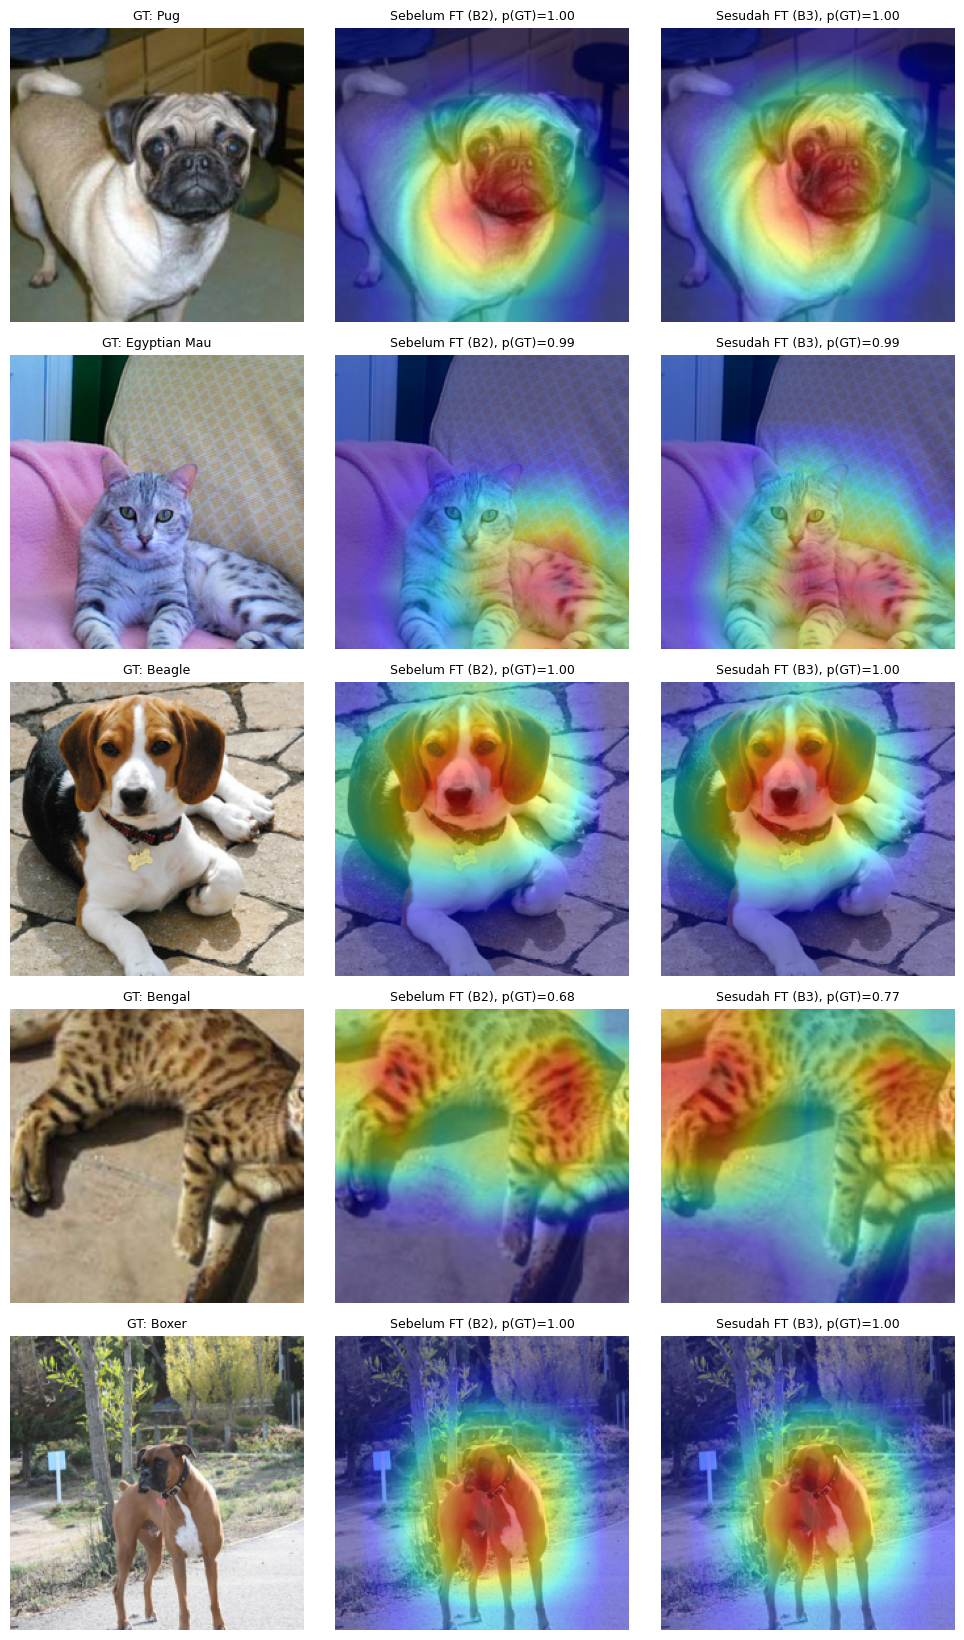

In [28]:
rng = np.random.RandomState(SEED)
show_ids = [rng.choice(np.where(labels[test_idx] == c)[0]) for c in rng.choice(NUM_CLASSES, 5, replace=False)]

fig, axes = plt.subplots(len(show_ids), 3, figsize=(10, 3.3 * len(show_ids)))
for row, i in zip(axes, show_ids):
    j, y = test_idx[i], labels[test_idx[i]]
    x = eval_transforms(images[j]).unsqueeze(0).to(device)
    img = np.asarray(TF.center_crop(images[j], 224))
    cb, pb = grad_cam(m_before, x, y)
    ca, pa = grad_cam(m_after, x, y)
    row[0].imshow(img); row[0].set_title(f"GT: {CLASS_NAMES[y]}", fontsize=9)
    row[1].imshow(img); row[1].imshow(cb, cmap="jet", alpha=0.45); row[1].set_title(f"Sebelum FT (B2), p(GT)={pb:.2f}", fontsize=9)
    row[2].imshow(img); row[2].imshow(ca, cmap="jet", alpha=0.45); row[2].set_title(f"Sesudah FT (B3), p(GT)={pa:.2f}", fontsize=9)
    for ax in row:
        ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "C5_gradcam_before_after.png", dpi=130); plt.show()

Grad-CAM test set:   0%|          | 0/299 [00:00<?, ?it/s]

Rata-rata korelasi CAM sebelum vs sesudah FT: 0.909 (median 0.950)


,mean_cam_corr
class,
Bengal,0.878
Egyptian Mau,0.911
British Shorthair,0.926
Russian Blue,0.862
Persian,0.802
Beagle,0.947
Basset Hound,0.948
Boxer,0.947
Pug,0.944


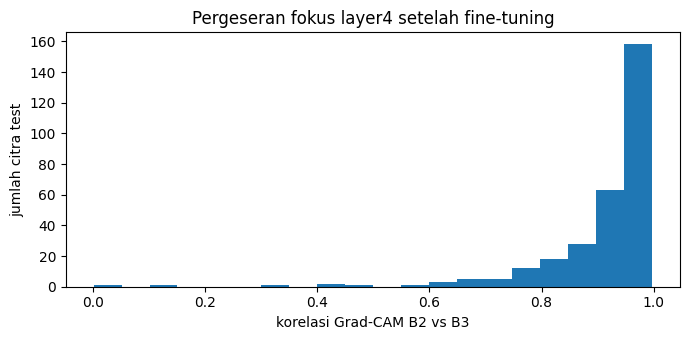

In [29]:
# Seberapa jauh fokus layer4 bergeser? korelasi CAM B2 vs B3 di seluruh test set
corrs = []
for i in tqdm(range(len(test_idx)), desc="Grad-CAM test set"):
    j, y = test_idx[i], labels[test_idx[i]]
    x = eval_transforms(images[j]).unsqueeze(0).to(device)
    cb, _ = grad_cam(m_before, x, y)
    ca, _ = grad_cam(m_after, x, y)
    corrs.append({"path": Path(paths[j]).name, "class": CLASS_NAMES[y], "cam_corr": np.corrcoef(cb.ravel(), ca.ravel())[0, 1]})
cam_df = pd.DataFrame(corrs)
cam_df.to_csv(OUT_DIR / "C5_gradcam_correlation.csv", index=False)

print(f"Rata-rata korelasi CAM sebelum vs sesudah FT: {cam_df['cam_corr'].mean():.3f} (median {cam_df['cam_corr'].median():.3f})")
display(cam_df.groupby("class")["cam_corr"].mean().loc[CLASS_NAMES].round(3).to_frame("mean_cam_corr"))

plt.figure(figsize=(7, 3.5))
plt.hist(cam_df["cam_corr"], bins=20)
plt.xlabel("korelasi Grad-CAM B2 vs B3"); plt.ylabel("jumlah citra test"); plt.title("Pergeseran fokus layer4 setelah fine-tuning")
plt.tight_layout(); plt.savefig(FIG_DIR / "C5_gradcam_corr_hist.png", dpi=150); plt.show()
del m_before, m_after

## 12. Ekspor: log mentah, requirements, README, ZIP

In [30]:
# gabungkan semua log per-epoch jadi satu file (bukti mentah angka di laporan)
all_logs = pd.concat([pd.read_csv(p) for p in sorted(LOG_DIR.glob("*_epochs.csv"))], ignore_index=True)
all_logs.to_csv(OUT_DIR / "all_epoch_logs.csv", index=False)

import matplotlib
req = "\n".join([
    f"torch=={torch.__version__.split('+')[0]}",
    f"torchvision=={torchvision.__version__.split('+')[0]}",
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"Pillow=={Image.__version__}",
    "tqdm",
    "tabulate",
]) + "\n"
(OUT_DIR / "requirements.txt").write_text(req)
print(req)

torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
Pillow==11.3.0
tqdm
tabulate



In [31]:
readme = f"""# Tugas 05 — Transfer Learning ResNet-18 pada Oxford-IIIT Pet (10 kelas)

Eksperimen B1–B5: from scratch, feature extraction, progressive fine-tuning, uji augmentasi, dan arsitektur pembanding (EfficientNet-B0, MobileNetV3-Small).

## Cara menjalankan
1. Buka notebook di Google Colab, pilih runtime **T4 GPU**.
2. Runtime → Run all. Dataset diunduh otomatis lewat `torchvision.datasets.OxfordIIITPet`.
3. Semua output tersimpan di `outputs/`.

Lokal: `pip install -r requirements.txt`, lalu jalankan notebook.

## Protokol
- Seed {SEED} (Python, NumPy, PyTorch), cuDNN deterministic.
- Batch size {CFG['batch_size']}, AdamW (weight decay {CFG['weight_decay']}), CrossEntropyLoss.
- Early stopping pada val loss, patience {CFG['patience']}, maksimal {CFG['max_epochs']} epoch; bobot epoch terbaik dipulihkan.
- Input 224×224, normalisasi ImageNet. Augmentasi hanya pada data latih.
- Kelas: {', '.join(CLASS_NAMES)}.

## Isi `outputs/`
| File | Isi |
|---|---|
| `config.json` | konfigurasi + environment |
| `split_manifest.csv` | daftar file per split (train/val/test) |
| `logs/<run>_epochs.csv`, `all_epoch_logs.csv` | log per epoch: loss, akurasi, waktu, LR per grup |
| `results_summary.csv` / `.json` | ringkasan metrik akhir tiap run |
| `predictions/<run>_test_predictions.csv` | prediksi + confidence tiap citra test |
| `C1_tabel_konsolidasi.csv` | tabel C1 |
| `C3_misclassified.csv` | kasus misklasifikasi (C3) |
| `C5_gradcam_correlation.csv` | korelasi Grad-CAM sebelum/sesudah fine-tuning |
| `figures/` | semua grafik |

Checkpoint (`checkpoints/`) tidak dimasukkan ke ZIP karena ukurannya besar.
"""
(OUT_DIR / "README.md").write_text(readme)

zip_base = Path("Tugas05_outputs")
tmp = Path("_export"); shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(OUT_DIR, tmp, ignore=shutil.ignore_patterns("checkpoints"))
shutil.make_archive(str(zip_base), "zip", tmp)
shutil.rmtree(tmp, ignore_errors=True)
print("ZIP:", str(zip_base) + ".zip")

ZIP: Tugas05_outputs.zip


## 13. Catatan

Analisis dan kesimpulan ditulis di laporan (C2–C4), berdasarkan angka di `results_summary.csv` dan `all_epoch_logs.csv`.

**Referensi kode:** Grad-CAM mengikuti Selvaraju et al. (2017), *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*, ICCV. Model dan bobot pretrained dari `torchvision.models`.